In [1]:
import sys
import os
import numpy as np
import jax
from jax import jit, grad, vmap, value_and_grad, jvp, lax, flatten_util
import jax.numpy as jnp
import optax
import jaxopt
from flax import linen as nn
file_path = os.getcwd()
project_root = os.path.dirname(os.path.dirname(file_path))
from Crunch.Auxiliary.utils import *
from Crunch.Models.layers import *
import random
#Additional
import time
import gc
# Libraries
import scipy.io
import scipy.integrate as integrate
import h5py
from sklearn.model_selection import train_test_split
from pyDOE import lhs
from typing import Tuple, List, Dict, Sequence
from functools import partial

# Plotting libraries
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib as mpl
from scipy.interpolate import griddata
# Progress tracking
from tqdm import tqdm, trange
# Inline plotting for notebooks
%matplotlib inline


In [2]:
cmap = 'RdBu_r'
num_colors=8
# Create a colormap
cmap = plt.get_cmap(cmap)
colors = [cmap(i) for i in np.linspace(0, 1, num_colors)]
colors=colors[:num_colors//4]+colors[3*num_colors//4:]
print(len(colors))
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=colors)

plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 20

4


# Settings and Problem Definition

In [3]:
Run_type = 'Rayleight-Bernard'
Mode='PINN'
num_layer=4
width_layer = 50 # neurons per layer
layers_net = num_layer*[width_layer] + [4]
Details= 'Forward'

# Running Details
Run_MODE='Train'
Save_name='Test_New_Models'

#Data
N_u = int(4e2)
N_r = int(1e5)   
N_i = int(1) #Datapoints   

# Architecture
embedding_degree=10
activation = 'sin'

#- Output Scaling if needed
u_scale=1
v_scale=1
p_scale=1
T_scale=1

#Optimization
num_gsteps  = 100*(10**3)
batch_size = 5000

# - Optimizer
lr0=2*10**(-3)
lrf=1.5*10**(-4)
decay_rate=0.9
decay_step=0

#- Enhancements RBA
use_RBA=True
lr_lambdas_0=5*10**(-1)
gamma=0.99

# SaveName
dataset_name = f'{Details}_RBA:{use_RBA}'

# Dataset Details
data_path="/users/jdtoscan/data/jdtoscan/AIV/Instant-AIV/DataSets/Rayleight_Bernard/data_Rae4.mat"
save_path=project_root+f'/Results/{Run_type}/{dataset_name}/'
big_data_path=save_path
grads_file=f'Fig3:{Save_name}-All_SNR.txt'
print(f'Analizing:{data_path}')
print(f'Analizing:{dataset_name}')


Analizing:/users/jdtoscan/data/jdtoscan/AIV/Instant-AIV/DataSets/Rayleight_Bernard/data_Rae4.mat
Analizing:Forward_RBA:True


### Random Seeds

In [4]:
# random key
seed_np=1234
key = jax.random.PRNGKey(seed_np)
key, subkey = jax.random.split(key, 2)
# Initialize NumPy seed
np.random.seed(seed_np)
# Initialize Python's random module seed
random.seed(seed_np)

### Initialize Folders

In [5]:
subdirs = ["General","Imgs", "Big_Data", "Data", "Flow_rate", "Errors","lambdas","residuals"]
paths = create_and_return_directories(save_path, dataset_name, subdirs)
result_path = paths["General"]
images_path = paths["Imgs"]
big_path = paths["Big_Data"]
flowrate_path = paths["Flow_rate"]
errors_path = paths["Errors"]
lambdas_path = paths["lambdas"]
residuals_path=paths["residuals"]


The general path is: /oscar/data/gk/jdtoscan/LLM/Documents/Results/Rayleight-Bernard/Forward_RBA:True/Forward_RBA:True/General/
The imgs path is: /oscar/data/gk/jdtoscan/LLM/Documents/Results/Rayleight-Bernard/Forward_RBA:True/Forward_RBA:True/Imgs/
The big data path is: /oscar/data/gk/jdtoscan/LLM/Documents/Results/Rayleight-Bernard/Forward_RBA:True/Forward_RBA:True/Big_Data/
The data path is: /oscar/data/gk/jdtoscan/LLM/Documents/Results/Rayleight-Bernard/Forward_RBA:True/Forward_RBA:True/Data/
The flow rate path is: /oscar/data/gk/jdtoscan/LLM/Documents/Results/Rayleight-Bernard/Forward_RBA:True/Forward_RBA:True/Flow_rate/
The errors path is: /oscar/data/gk/jdtoscan/LLM/Documents/Results/Rayleight-Bernard/Forward_RBA:True/Forward_RBA:True/Errors/
The lambdas path is: /oscar/data/gk/jdtoscan/LLM/Documents/Results/Rayleight-Bernard/Forward_RBA:True/Forward_RBA:True/lambdas/
The residuals path is: /oscar/data/gk/jdtoscan/LLM/Documents/Results/Rayleight-Bernard/Forward_RBA:True/Forward_

# Data Processing


### Load/Generate Data

In [6]:
data=scipy.io.loadmat(data_path)
X=data['x'].flatten()[:,None]
Y=data['y'].flatten()[:,None]
u=data['u'].flatten()[:,None]
v=data['v'].flatten()[:,None]
theta=data['theta'].flatten()[:,None]
Ra=1*10**(int(data_path[-5]))
Pr=0.71
sqrt_Pr_Ra=np.sqrt(Pr/Ra)
sqrt_RaPr=np.sqrt(1/(Pr*Ra))
print(sqrt_Pr_Ra)
print(sqrt_RaPr)

0.008426149773176359
0.011867816581938534


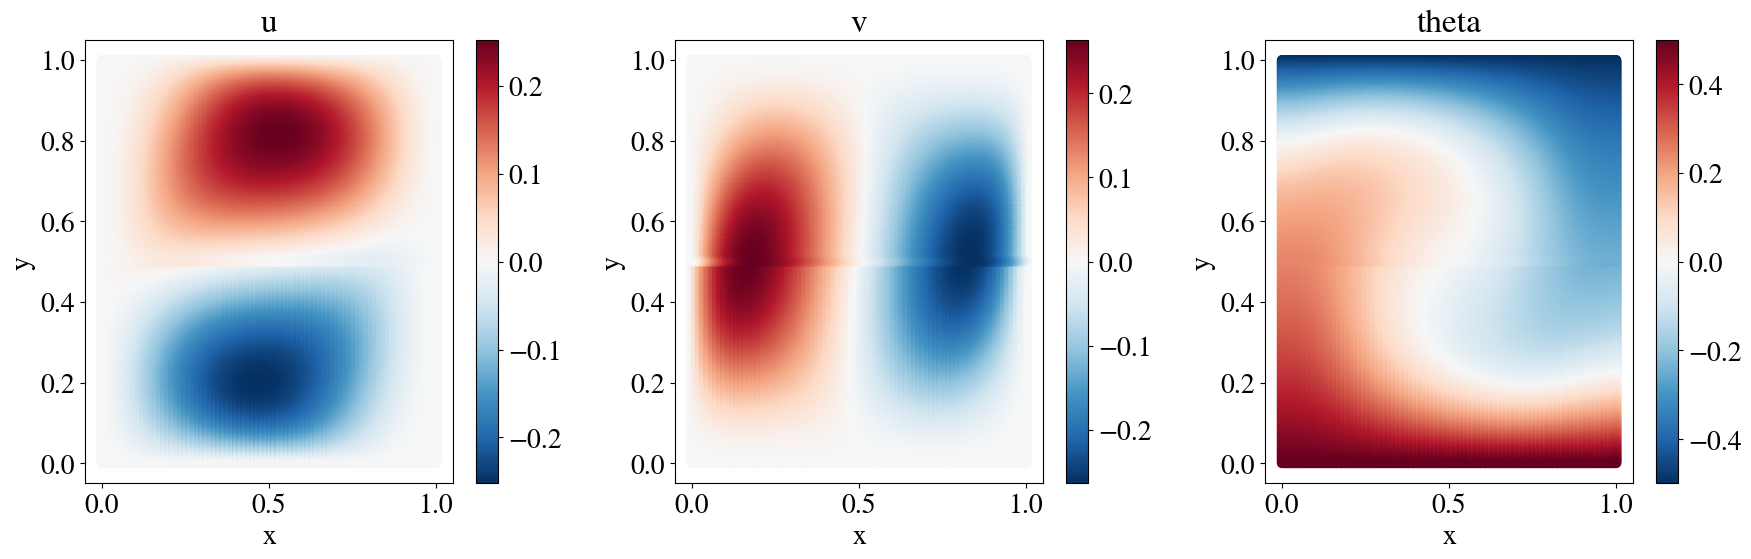

In [7]:
plt.figure(figsize=(18, 6))
# Scatter plot of u vs x and y with colorbar
plt.subplot(1, 3, 1)
scatter_u = plt.scatter(X, Y,c=u, cmap='RdBu_r')
plt.colorbar(scatter_u)
plt.title('u')
plt.xlabel('x')
plt.ylabel('y')
# Scatter plot of v vs x and y with colorbar
plt.subplot(1, 3, 2)
scatter_v = plt.scatter(X, Y, c=v, cmap='RdBu_r')
plt.colorbar(scatter_v)
plt.title('v')
plt.xlabel('x')
plt.ylabel('y')
# Scatter plot of theta vs x and y with colorbar
plt.subplot(1, 3, 3)
scatter_theta = plt.scatter(X, Y, c=theta, cmap='RdBu_r')
plt.colorbar(scatter_theta)
plt.title('theta')
plt.xlabel('x')
plt.ylabel('y')
plt.tight_layout()
plt.show()


In [8]:
X_star=np.hstack([X,Y])
u_star=np.hstack([u,v,theta])

###  Identify BCs

In [9]:
# Improved range calculation
lb, ub = np.min(X_star, axis=0), np.max(X_star, axis=0)
x_min, y_min = lb[0], lb[1]
x_max, y_max = ub[0], ub[1]
print(f"x_min: {x_min}, y_min: {y_min}, x_max: {x_max}, y_max: {y_max}")

def extract_boundary_conditions(X_star, u_star, value, axis):
    idx_bc = np.argwhere(X_star[:, axis] == value).flatten()
    return X_star[idx_bc][1:-1] if axis == 0 else X_star[idx_bc], u_star[idx_bc][1:-1] if axis == 0 else u_star[idx_bc]

xx1, vv1 = extract_boundary_conditions(X_star, u_star, x_min, 0)
xx2, vv2 = extract_boundary_conditions(X_star, u_star, x_max, 0)
xx3, vv3 = extract_boundary_conditions(X_star, u_star, y_min, 1)
xx4, vv4 = extract_boundary_conditions(X_star, u_star, y_max, 1)

# Combining boundary conditions
X_bcs_1 = np.vstack([xx1, xx2])
V_bcs_1 = np.vstack([vv1, vv2])
print(f"X_bcs Top/Bottom shape: {X_bcs_1.shape}, V_bcs shape: {V_bcs_1.shape}")
X_bcs_2 = np.vstack([xx3, xx4])
V_bcs_2 = np.vstack([vv3, vv4])
print(f"X_bcs Sides shape: {X_bcs_2.shape}, V_bcs shape: {V_bcs_2.shape}")
np.random.seed(seed_np)
idx = np.random.choice(len(X_bcs_1), N_u, replace=False)
X_bcs_1, V_bcs_1 = X_bcs_1[idx], V_bcs_1[idx]
idx = np.random.choice(len(X_bcs_2), N_u, replace=False)
X_bcs_2, V_bcs_2 = X_bcs_2[idx], V_bcs_2[idx]
print(f"X_bcs Top/Bottom shape: {X_bcs_2.shape}, V_bcs shape: {V_bcs_1.shape}")
print(f"X_bcs Sides shape: {X_bcs_1.shape}, V_bcs shape: {V_bcs_2.shape}")

x_min: 0.0, y_min: 0.0, x_max: 1.0, y_max: 1.0
X_bcs Top/Bottom shape: (1900, 2), V_bcs shape: (1900, 3)
X_bcs Sides shape: (632, 2), V_bcs shape: (632, 3)
X_bcs Top/Bottom shape: (400, 2), V_bcs shape: (400, 3)
X_bcs Sides shape: (400, 2), V_bcs shape: (400, 3)


## Define Collocation Points

In [10]:
X_r = lb + (ub-lb)*lhs(2, N_r)
print(lb,ub)

[0. 0.] [1. 1.]


### Group Datasets


In [11]:
X_res=X_r
X_BCs_1=np.hstack([X_bcs_1,V_bcs_1])
X_BCs_2=np.hstack([X_bcs_2,V_bcs_2])
X_sol=np.hstack((X_star,u_star))

### Select Data for inverse Problems

In [12]:
idx = np.random.choice(len(X_sol), N_i, replace=False).flatten()
X_data= X_sol[idx]

### Final Data summary and storing

In [13]:
### Expected shape (N_total_points, N_inputs+N_available_outpus)
print(f'Bounds for BCs Data Sides with {X_BCs_1.shape} points:')
print(np.min(X_BCs_1,axis=0))
print(np.max(X_BCs_1,axis=0))
print(f'Bounds for BCs Data Top/Bottom with {X_BCs_2.shape} points:')
print(np.min(X_BCs_2,axis=0))
print(np.max(X_BCs_2,axis=0))
print(f'Bounds for Residual Data with {X_res.shape} points:')
print(np.min(X_res,axis=0))
print(np.max(X_res,axis=0))
print(f'Bounds for Solution Data with {X_sol.shape} points:')
print(np.min(X_sol,axis=0))
print(np.max(X_sol,axis=0))
print(f'Bounds for Data Data with {X_data.shape} points:')
print(np.min(X_data,axis=0))
print(np.max(X_data,axis=0))

Bounds for BCs Data Sides with (400, 5) points:
[ 0.       0.       0.       0.      -0.49792]
[1.     0.9972 0.     0.     0.5   ]
Bounds for BCs Data Top/Bottom with (400, 5) points:
[ 0.   0.   0.   0.  -0.5]
[1.  1.  0.  0.  0.5]
Bounds for Residual Data with (100000, 2) points:
[3.77143015e-06 2.59881669e-06]
[0.99999037 0.99999454]
Bounds for Solution Data with (300832, 5) points:
[ 0.       0.      -0.2523  -0.26368 -0.5    ]
[1.      1.      0.2523  0.26369 0.5    ]
Bounds for Data Data with (1, 5) points:
[ 0.78481  0.2577  -0.12107 -0.1547  -0.10376]
[ 0.78481  0.2577  -0.12107 -0.1547  -0.10376]


In [14]:
dataset = {
    'Bcs_lr': X_BCs_1,
    'Bcs_tb': X_BCs_2,
    'Res': X_res,
    'Data': X_data,
    'Error_data': X_data,
    'GT': X_sol
}

# Data Hyperparameters
lam = {
    'Bcs_lr': 100,
    'Bcs_tb': 100,
    'Res': 1,
    'Data': 1000,
    'Error_data': 10,
    'GT': 1 # Dummy variable
}

# Knowledge based on the problem
neq = {
    'Bcs_lr': 3,
    'Bcs_tb': 3,
    'Res': 4,
    'Data': 3,
    'Error_data': 3,
    'GT': 1 # Dummy variable
}

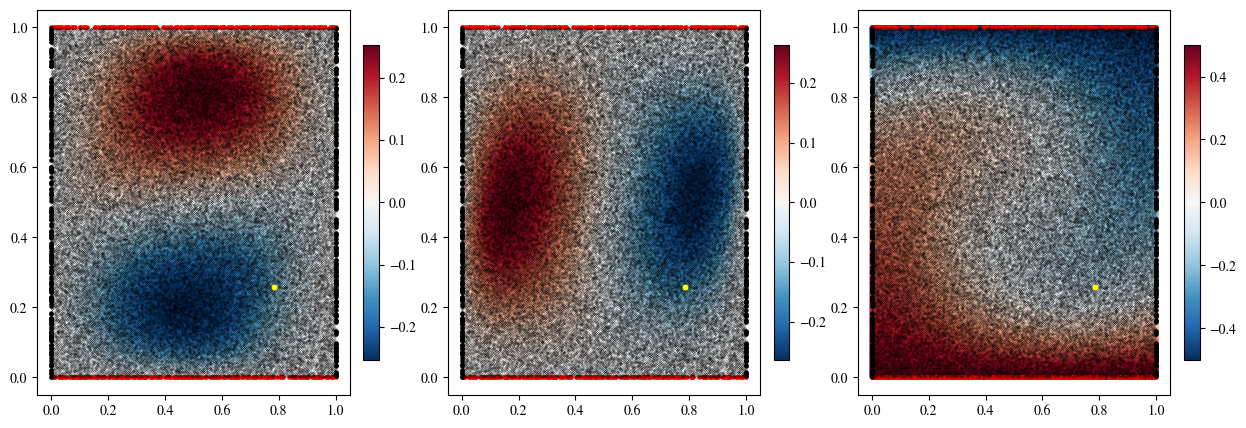

In [15]:
figsize=(15,5)
fig = plt.figure(figsize=figsize)
plt.rcParams['font.size'] = '10'
ax = fig.add_subplot(1, 3, 1)
img = ax.scatter(dataset['GT'][:,0], dataset['GT'][:,1],c=dataset['GT'][:,2:3], cmap='RdBu_r',s=5)
fig.colorbar(img,fraction=0.046, pad=0.04)
img = ax.scatter(dataset['Bcs_tb'][:,0], dataset['Bcs_tb'][:,1],c='red',s=5)
img = ax.scatter(dataset['Bcs_lr'][:,0], dataset['Bcs_lr'][:,1],c='k',s=5)
img = ax.scatter(dataset['Res'][:,0], dataset['Res'][:,1],c='k',s=0.01)
img = ax.scatter(dataset['Data'][:,0], dataset['Data'][:,1],c='yellow',s=10)
ax = fig.add_subplot(1, 3, 2)
img = ax.scatter(dataset['GT'][:,0], dataset['GT'][:,1],c=dataset['GT'][:,3:4], cmap='RdBu_r',s=5)
fig.colorbar(img,fraction=0.046, pad=0.04)
img = ax.scatter(dataset['Bcs_tb'][:,0], dataset['Bcs_tb'][:,1],c='red',s=5)
img = ax.scatter(dataset['Bcs_lr'][:,0], dataset['Bcs_lr'][:,1],c='k',s=5)
img = ax.scatter(dataset['Res'][:,0], dataset['Res'][:,1],c='k',s=0.01)
img = ax.scatter(dataset['Data'][:,0], dataset['Data'][:,1],c='yellow',s=10)
ax = fig.add_subplot(1, 3, 3)
img = ax.scatter(dataset['GT'][:,0], dataset['GT'][:,1],c=dataset['GT'][:,4:5], cmap='RdBu_r',s=5)
fig.colorbar(img,fraction=0.046, pad=0.04)
img = ax.scatter(dataset['Bcs_tb'][:,0], dataset['Bcs_tb'][:,1],c='red',s=5)
img = ax.scatter(dataset['Bcs_lr'][:,0], dataset['Bcs_lr'][:,1],c='k',s=5)
img = ax.scatter(dataset['Res'][:,0], dataset['Res'][:,1],c='k',s=0.01)
img = ax.scatter(dataset['Data'][:,0], dataset['Data'][:,1],c='yellow',s=10)
plt.show()

# Data Preparation (General)

### Define batchsizes

In [16]:
### Expected shape (batchsize, N_inputs+N_available_outpus)
lengths = []
for key in dataset.keys():
    if key != 'GT':
        lengths.append(len(dataset[key]))
        print(f'Length of {key} dataset: {len(dataset[key])}')
    else:
        print(f'Length of GT dataset: {len(dataset[key])} (not used for overall batch size calculation)')

N_train = int(np.max(lengths))

if batch_size < 0:
    batch_size = N_train

All_its = int(np.ceil(N_train / batch_size))
print(f'The total number of iterations will be:{All_its}')
BATCH_SIZES = {}

for key in dataset.keys():
    if key == 'Res':
        BATCH_SIZES[key] = int(np.ceil(len(dataset[key]) / All_its))
        print(f'Batch size for {key} dataset: {BATCH_SIZES[key]}')
        
    else:
        if not(key == 'GT'):
        # For other keys, calculate batch size normally
            BATCH_SIZES[key] = len(dataset[key])
            print(f'Batch size for {key} dataset: {BATCH_SIZES[key]}')


Length of Bcs_lr dataset: 400
Length of Bcs_tb dataset: 400
Length of Res dataset: 100000
Length of Data dataset: 1
Length of Error_data dataset: 1
Length of GT dataset: 300832 (not used for overall batch size calculation)
The total number of iterations will be:20
Batch size for Bcs_lr dataset: 400
Batch size for Bcs_tb dataset: 400
Batch size for Res dataset: 5000
Batch size for Data dataset: 1
Batch size for Error_data dataset: 1


### Initialize multiplers for RBA

In [17]:
# Expected shape (N_total_points, N_outputs) IMPORTANT THE WEIGHTS ARE APPLIED POINTWISE SO THERE SHOULD BE AS MANY AS TOTAL POINTS NOT AS BATCH_SIZE
lambdas={}
for key in dataset.keys():
    np.random.seed(seed_np)
    lambdas[key] = np.zeros([len(dataset[key]), neq[key]])+0.1
    print(f'Lambda shape for {key} dataset: {lambdas[key].shape}')


Lambda shape for Bcs_lr dataset: (400, 3)
Lambda shape for Bcs_tb dataset: (400, 3)
Lambda shape for Res dataset: (100000, 4)
Lambda shape for Data dataset: (1, 3)
Lambda shape for Error_data dataset: (1, 3)
Lambda shape for GT dataset: (300832, 1)


## Define Model

In [18]:
class UnitSquareNormalization(nn.Module):
    min_vals: Sequence[float]
    max_vals: Sequence[float]
    epsilon: float = 1e-8
    def setup(self):
        min_arr = jnp.asarray(self.min_vals, dtype=jnp.float32)
        max_arr = jnp.asarray(self.max_vals, dtype=jnp.float32)
        data_range = max_arr - min_arr
        self.scale = 1.0 / (data_range + self.epsilon)
        self.shift = -min_arr / (data_range + self.epsilon)
    def __call__(self, x: jnp.ndarray) -> jnp.ndarray:
        return x * self.scale + self.shift
class Random_Fourier_Embedding(nn.Module):
    degree: int
    s: float = 10.0
    @nn.compact
    def __call__(self, X: Array) -> Array:
        input_features = X.shape[-1]
        def b_init(key, shape, dtype=jnp.float32):
            return self.s * jax.random.normal(key, shape, dtype)
        B = self.param('B', b_init, (input_features, self.degree))
        X_proj = jnp.dot(X, B)
        return jnp.concatenate([X, jnp.sin(X_proj), jnp.cos(X_proj)], axis=-1)
class WNmMLP(nn.Module):
    features: Sequence[int]
    activation_fn: callable = nn.activation.tanh
    @nn.compact
    def __call__(self, X):
        init = nn.initializers.variance_scaling(scale=1.0, mode="fan_in", distribution="uniform")
        U = self.activation_fn(WN_layer(self.features[0], kernel_init=init)(X))
        V = self.activation_fn(WN_layer(self.features[0], kernel_init=init)(X))
        H = self.activation_fn(WN_layer(self.features[0], kernel_init=init)(X))
        for fs in self.features[1:-1]:
            Z = WN_layer(fs, kernel_init=init)(H)
            Z = self.activation_fn(Z)
            H = (jnp.ones_like(Z)-Z)*U + Z*V
        H = WN_layer(self.features[-1], kernel_init=init)(H)
        return H
class PINN(nn.Module):
    embedding_degree:int
    min_vals: Sequence[float] 
    max_vals: Sequence[float] 
    features: Sequence[int]
    activation_fn: callable = nn.activation.tanh
    def setup(self):
        self.normalization = UnitSquareNormalization(min_vals=self.min_vals,max_vals=self.max_vals)
        self.embedding = Random_Fourier_Embedding(degree=self.embedding_degree) 
        self.WNmMLP = WNmMLP(features=self.features,activation_fn=self.activation_fn)
    @nn.compact
    def __call__(self, x):
        x=self.normalization(x)
        x=self.embedding(x)
        H=self.WNmMLP(x)
        return H

### Initialize Model

In [19]:
activation_fn =lambda x: jnp.sin(x)
min_vals=dataset['Res'].min(0,keepdims=False)# Notice that we use the collocation Points
max_vals=dataset['Res'].max(0,keepdims=False)# Expected  shape (N_input_dim,)
n_inputs=dataset['Res'].shape[-1]
model = PINN(embedding_degree=embedding_degree,
            min_vals=min_vals,
            max_vals=max_vals,
            features=layers_net,
            activation_fn=activation_fn)

### Initialize Parameters

In [20]:
params = model.init(subkey, dataset['Res'][100,:])
pinn_fn = jax.jit(model.apply)
total_params = sum(x.size for x in jax.tree_util.tree_leaves(params))
print(total_params )

11628


#### Initialize Optimizer

In [21]:
optimizer,decay_step = initialize_optimizer(lr0, decay_rate, lrf, decay_step, num_gsteps,optimizer_type='Adamw')
opt_state = optimizer.init(params)

Optimizer adamw
Weight decay: 1e-05
The decay step will be 4067.5539984190036


## Final model

In [22]:
def u_PINN(params, x_batch):
    predictions = pinn_fn(params, x_batch) 
    u = u_scale * predictions[:, 0:1]
    v = v_scale * predictions[:, 1:2]
    p = p_scale * predictions[:, 2:3]
    T = T_scale * predictions[:, 3:4]
    return u, v, p, T

## Equations and Residuals

In [23]:
scale_p=1       # scaled pressure required for stability in some cases
nu_1=sqrt_Pr_Ra # equivalent viscocisty
nu_2=sqrt_RaPr

def Rayleight_Bernard_eq(params, X_batch, alpha):
    u_fn = lambda x: pinn_fn(params, x)[:, 0:1] * u_scale
    v_fn = lambda x: pinn_fn(params, x)[:, 1:2] * v_scale
    p_fn = lambda x: pinn_fn(params, x)[:, 2:3] * p_scale
    T_fn = lambda x: pinn_fn(params, x)[:, 3:4] * T_scale

    # 2. Get the primary model outputs for the batch
    u = u_fn(X_batch)
    v = v_fn(X_batch)
    T = T_fn(X_batch)

    # 3. Create batched tangent vectors for x and y derivatives
    tangents_x = jnp.zeros_like(X_batch)
    tangents_x = tangents_x.at[:, 0].set(1.0)
    
    tangents_y = jnp.zeros_like(X_batch)
    tangents_y = tangents_y.at[:, 1].set(1.0)

    # --- Derivatives of u (1st and 2nd order) ---
    u_x, u_xx = hvp_fwdfwd(u_fn, (X_batch,), (tangents_x,), return_primals=True)
    u_y, u_yy = hvp_fwdfwd(u_fn, (X_batch,), (tangents_y,), return_primals=True)
    
    # --- Derivatives of v (1st and 2nd order) ---
    v_x, v_xx = hvp_fwdfwd(v_fn, (X_batch,), (tangents_x,), return_primals=True)
    v_y, v_yy = hvp_fwdfwd(v_fn, (X_batch,), (tangents_y,), return_primals=True)

    # --- Derivatives of p (1st order ONLY) ---
    p_x = jvp(p_fn, (X_batch,), (tangents_x,))[1]
    p_y = jvp(p_fn, (X_batch,), (tangents_y,))[1]

    # --- Derivatives of T (1st and 2nd order) ---
    T_x, T_xx = hvp_fwdfwd(T_fn, (X_batch,), (tangents_x,), return_primals=True)
    T_y, T_yy = hvp_fwdfwd(T_fn, (X_batch,), (tangents_y,), return_primals=True)

    # eq1: x-Momentum
    eq1 = ( (u * u_x + v * u_y) \
          - (nu_1) * (u_xx + u_yy) \
          + p_x * scale_p ) / scale_p \
          - jnp.sin(alpha) * T

    # eq2: y-Momentum
    eq2 = ( (u * v_x + v * v_y) \
          - (nu_1) * (v_xx + v_yy) \
          + p_y * scale_p \
          - jnp.cos(alpha) * T ) / scale_p

    # eq3: Continuity (Mass)
    eq3 = u_x + v_y
    
    # eq4: Temperature
    eq4 = (u * T_x + v * T_y) \
          - (nu_2) * (T_xx + T_yy)

    return eq1, eq2, eq3, eq4

## Custom Boundary Conditions Constraints

In [24]:
def Neuman_BCs(params, X_batch):
    T_fn = lambda x: pinn_fn(params, x)[:, 3:4] * T_scale
    tangents_x = jnp.zeros_like(X_batch)
    tangents_x = tangents_x.at[:, 0].set(1.0)
    T_x = jvp(T_fn, (X_batch,), (tangents_x,))[1]
    
    return T_x
u_model = jax.jit(u_PINN)
Neuman_BCs_jit = jax.jit(Neuman_BCs)
PDE_eq = jax.jit(Rayleight_Bernard_eq)

# Loss Functions

### Error Functions


In [25]:
Train_Error_fn = lambda pred, exact, weight=1: jnp.mean(weight * jnp.square(pred - exact))
Test_Error_fn=lambda u, u_gt: jnp.linalg.norm(u.flatten() - u_gt.flatten(), 2) / jnp.linalg.norm(u_gt.flatten(), 2)

### Update Scheme

In [26]:
@jit
def update(params, lambdas, alpha, opt_state, dataset: Dict[str, np.ndarray], batch_indices: Dict[str, np.ndarray]):
    def _compute_rba_multipliers(residuals_batch,    
                                 lambdas_full,        
                                 batch_indices_key,   
                                 rba_params):        
        gamma, lr_lambdas_0, use_RBA = rba_params
        lambdas_old_batch = lambdas_full[batch_indices_key]
        lam_key_new = (gamma) * lambdas_old_batch + \
                      lr_lambdas_0 * residuals_batch / (jnp.max(residuals_batch, axis=0) + 1e-8)
        lam_key_new = project_simplex(lam_key_new)
        multipliers_batch = lam_key_new * use_RBA + 0.1
        lambdas_new_full = lambdas_full.at[batch_indices_key].set(lam_key_new)
        return multipliers_batch, lambdas_new_full
    def project_simplex(lam_f):
        return (lam_f/(jnp.sum(lam_f, axis=0)+10**(-8)))*len(lam_f)
    lambdas_0 = lambdas 
    rba_params = (gamma, lr_lambdas_0, use_RBA)
    def loss_fn(params):
        # Initialize dictionaries
        residuals = {}
        multipliers = {}
        updated_lambdas = lambdas_0.copy()
        
        res1, res2, res3, res4 = PDE_eq(params, dataset['Res'][:, :n_inputs], alpha)
        residuals['Res'] = jnp.abs(jnp.hstack([res1, res2, res3, res4]))
        
        multipliers['Res'], updated_lambdas['Res'] = _compute_rba_multipliers(
            residuals['Res'], 
            updated_lambdas['Res'],  
            batch_indices['Res'],
            rba_params
        )

        u_pred_tb, v_pred_tb,_, T_pred_tb = u_model(params, dataset['Bcs_tb'][:, :n_inputs])
        pred_array_tb = jnp.hstack([u_pred_tb, v_pred_tb, T_pred_tb])
        target_array_tb = dataset['Bcs_tb'][:, 2:5]
        residuals['Bcs_tb'] = jnp.abs(pred_array_tb - target_array_tb)

        multipliers['Bcs_tb'], updated_lambdas['Bcs_tb'] = _compute_rba_multipliers(
            residuals['Bcs_tb'],
            updated_lambdas['Bcs_tb'],
            batch_indices['Bcs_tb'],
            rba_params
        )
        u_pred_lr, v_pred_lr, _ ,_= u_model(params, dataset['Bcs_lr'][:, :n_inputs])
        neu_pred_lr = Neuman_BCs(params, dataset['Bcs_lr'][:, :n_inputs])
        pred_array_lr = jnp.hstack([u_pred_lr, v_pred_lr, neu_pred_lr])
        target_array_lr = jnp.zeros_like(pred_array_lr)
        residuals['Bcs_lr'] = jnp.abs(pred_array_lr - target_array_lr)
        multipliers['Bcs_lr'], updated_lambdas['Bcs_lr'] = _compute_rba_multipliers(
            residuals['Bcs_lr'],
            updated_lambdas['Bcs_lr'], 
            batch_indices['Bcs_lr'],
            rba_params
        )
        
        # --- 4. Calculate Final Loss ---
        loss_vals = {
            'Mx':     lam['Res'] * Train_Error_fn(residuals['Res'][:, 0:1], 0.0, weight=multipliers['Res'][:, 0:1]),
            'My':     lam['Res'] * Train_Error_fn(residuals['Res'][:, 1:2], 0.0, weight=multipliers['Res'][:, 1:2]),
            'Mass':   lam['Res'] * Train_Error_fn(residuals['Res'][:, 2:3], 0.0, weight=multipliers['Res'][:, 2:3]),
            'MT':     lam['Res'] * Train_Error_fn(residuals['Res'][:, 3:4], 0.0, weight=multipliers['Res'][:, 3:4]),
            'Bcs_tb': lam['Bcs_tb'] * Train_Error_fn(residuals['Bcs_tb'], 0.0, weight=multipliers['Bcs_tb']),
            'Bcs_lr': lam['Bcs_lr'] * Train_Error_fn(residuals['Bcs_lr'], 0.0, weight=multipliers['Bcs_lr']),
        }

        total_loss = sum(loss_vals.values())
        return total_loss, (loss_vals, updated_lambdas)
    
    grad_fn = value_and_grad(loss_fn, has_aux=True)
    (_, (losses_dict, updated_lambdas)), grads = grad_fn(params)

    updates, opt_state = optimizer.update(grads, opt_state, params)
    params = optax.apply_updates(params, updates)

    return params, updated_lambdas, opt_state, losses_dict

# Training


In [27]:
def sample_points_PDF(it, batch_sizes, dataset, lambdas,k=1,c=0.5):
    key = jax.random.PRNGKey(it) 
    batch_indices = {}
    for data_key in batch_sizes: 
        key, subkey = jax.random.split(key) 
        lambdas_key = (jnp.sum(lambdas[data_key], axis=1))**k
        lambdas_key = lambdas_key / lambdas_key.mean() + c
        p = lambdas_key / lambdas_key.sum()
        batch_indices[data_key] = jax.random.choice(
            subkey, 
            len(dataset[data_key]), 
            shape=(batch_sizes[data_key],), 
            p=p
        )
    return batch_indices

In [28]:
@partial(jax.jit, static_argnames=['key'])
def compute_error_metrics(params, key='GT'):
    X_batch = dataset[key][:, 0:2]    
    u_gt = dataset[key][:, 2:3]
    v_gt = dataset[key][:, 3:4]
    T_gt = dataset[key][:, 4:5]    
    u_pred, v_pred, _, T_pred = u_model(params, X_batch)
    error_u = Test_Error_fn(u_pred, u_gt)
    error_v = Test_Error_fn(v_pred, v_gt)
    error_T = Test_Error_fn(T_pred, T_gt)
    return error_u, error_v, error_T

In [29]:
if Run_MODE=='Train':
    epoch_losses = []
    log_loss     = []
    log_epoch    = []
    log_lambdas  = []
    log_idxs = []
    log_error_u  = []
    log_error_v  = []
    start_time = time.time()
    running_time = 0
    it = 0
    key = jax.random.PRNGKey(seed_np)
    key, subkey = jax.random.split(key)
    k_samp=1/2
    c_samp=0.1
    alpha=0.0
    while it <=num_gsteps:
        #Sample Points
        batch_indices=sample_points_PDF(it,BATCH_SIZES,dataset,lambdas,k=k_samp,c=c_samp)
        batch_data = {key: dataset[key][batch_indices[key]] for key in BATCH_SIZES}
        #Update parameters
        params,lambdas, opt_state, batch_losses = update(
        params,lambdas,alpha, opt_state, batch_data,batch_indices)
        # Print and Store
        if it%100==0:
            log_lambdas.append(jax.device_get(lambdas['Res']))
            log_idxs.append(jax.device_get(batch_indices['Res']))
            if it % 1000 == 0:
                if it==10000:
                    alpha=jnp.pi/4
                elif it==30000:
                    alpha=jnp.pi/6
                elif it==60000:
                    alpha=0
                error_u, error_v, error_T= compute_error_metrics(params)
                # Loss computation
                loss_avg_dict = {key: jax.device_get(batch_losses[key]) for key in batch_losses.keys()}
                loss_avg_dict['RL2_u']=error_u
                loss_avg_dict['RL2_v']=error_v
                loss_avg_dict['RL2_T']=error_T
                loss_avg_dict['alpha']=alpha

                log_loss.append(loss_avg_dict)
                loss =sum(loss_avg_dict.values())

                # Lambda metrics
                lambda_res_metrics = {
                    "Max": np.max(lambdas['Res']),
                    "Min": np.min(lambdas['Res']),
                    "Mean": np.mean(lambdas['Res'])
                }

                lambda_data_metrics = {
                    "Max": np.max(lambdas['Bcs_lr']),
                    "Min": np.min(lambdas['Bcs_lr']),
                    "Mean": np.mean(lambdas['Bcs_lr'])
                }

                # Compute learning rate (assuming you've defined lr0, decay_rate, decay_step earlier in the code)
                lr = lr0 * decay_rate ** (it / decay_step)

                print("-" * 100)
                print(f"It: {it:d}, Total Loss: {loss:.3e}, RL2_u: {error_u:.3e}, RL2_v: {error_v:.3e},RL2_T: {error_T:.3e}")
                print(f"It: {it:d}, alpha: {alpha:.3e}")

                for key, value in loss_avg_dict.items():
                    print(f"Loss {key.capitalize()}: {value:.3e}")

                print(f"Lambda PDE (Max): {lambda_res_metrics['Max']:.3e}, Lambda PDE (Min): {lambda_res_metrics['Min']:.3e}, Lambda PDE (Mean): {lambda_res_metrics['Mean']:.3e}")
                print(f"Lambda Data (Max): {lambda_data_metrics['Max']:.3e}, Lambda Data (Min): {lambda_data_metrics['Min']:.3e}, Lambda Data (Mean): {lambda_data_metrics['Mean']:.3e}")
                print(f'Iteration time: {time.time() - start_time:.2f}s, Total Time: {running_time:.2f}h, Iteration/Total iterations: {it:.2f}/{num_gsteps:.2f}, Lr: {lr:.1e}')

                sys.stdout.flush()
                start_time = time.time()
        if it % 50000 == 0:
            save_list(log_loss,result_path,f'{dataset_name}-_loss')

        it += 1

----------------------------------------------------------------------------------------------------
It: 0, Total Loss: 3.502e+03, RL2_u: 4.740e+00, RL2_v: 4.955e+00,RL2_T: 2.985e+00
It: 0, alpha: 0.000e+00
Loss Bcs_lr: 2.618e+03
Loss Bcs_tb: 9.428e+01
Loss Mt: 1.232e+02
Loss Mass: 2.415e+02
Loss Mx: 1.959e+02
Loss My: 2.166e+02
Loss Rl2_u: 4.740e+00
Loss Rl2_v: 4.955e+00
Loss Rl2_t: 2.985e+00
Loss Alpha: 0.000e+00
Lambda PDE (Max): 3.208e+00, Lambda PDE (Min): 1.000e-01, Lambda PDE (Mean): 1.438e-01
Lambda Data (Max): 2.626e+00, Lambda Data (Min): 1.000e-01, Lambda Data (Mean): 6.590e-01
Iteration time: 68.65s, Total Time: 0.00h, Iteration/Total iterations: 0.00/100000.00, Lr: 2.0e-03
----------------------------------------------------------------------------------------------------
It: 1000, Total Loss: 4.302e+00, RL2_u: 1.013e+00, RL2_v: 1.086e+00,RL2_T: 1.205e+00
It: 1000, alpha: 0.000e+00
Loss Bcs_lr: 3.052e-02
Loss Bcs_tb: 2.418e-02
Loss Mt: 4.070e-01
Loss Mass: 1.506e-01
Loss M

## Losses and Errors

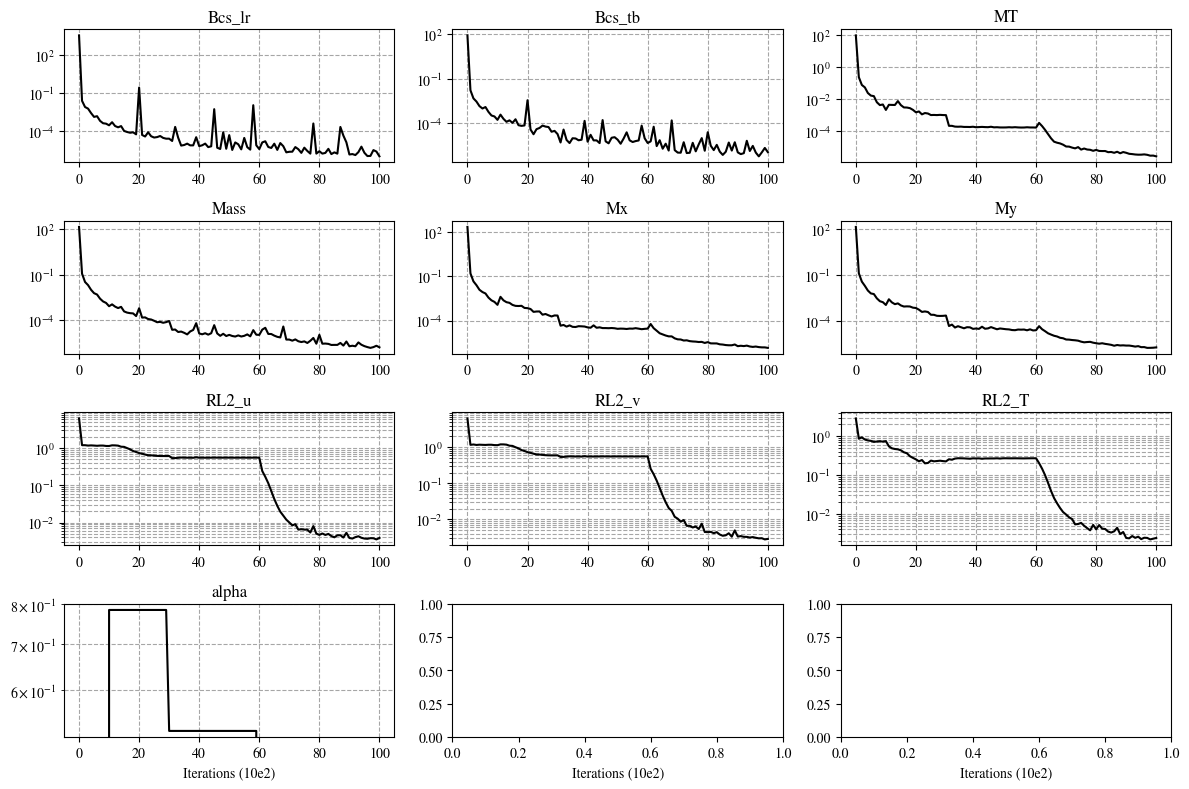

In [ ]:
def plot_losses_grid(log_loss):
    
    titles = list(log_loss[0].keys())
    
    # Make sure the subplot grid dimensions match the number of titles
    num_rows = (len(titles) + 2) // 3  # Add 2 to round up
    
    fig, axs = plt.subplots(num_rows, 3, figsize=(12, 8))

    # Ensure axs is a 2D array
    if num_rows == 1:
        axs = np.array([axs])

    for i, title in enumerate(titles):
        row = i // 3
        col = i % 3
        ax = axs[row][col]

        # Extract values for a specific loss from all dictionary entries
        loss_values = [entry[title] for entry in log_loss]

        ax.plot(loss_values, label=title, color='k')
        ax.set_title(title)
        ax.set_yscale('log')  # set y-axis to log scale
        ax.grid(True, which="both", ls="--", c='0.65')

    for ax in axs[-1, :]:
        ax.set_xlabel('Iterations (10e2)')

    plt.tight_layout()

# Call the function
plot_losses_grid(log_loss)
plt.savefig(result_path + f'Losses.png')
plt.show()


# Plots

In [ ]:
u_fx, v_fx, p_fx , T_fx  = u_model(params)
# Further computations for errors if any
u_pred  = vmap(u_fx, (0))(dataset['GT'][:,0:2])[:,None]
v_pred  = vmap(v_fx, (0))(dataset['GT'][:,0:2])[:,None]
T_pred  = vmap(T_fx, (0))(dataset['GT'][:,0:2])[:,None]

RL2_u = relative_error2(u_pred, dataset['GT'][:,2:3])
RL2_v = relative_error2(v_pred, dataset['GT'][:,3:4])
RL2_T = relative_error2(T_pred, dataset['GT'][:,4:5])
print(RL2_u,RL2_v,RL2_T)

0.0038851239925370086 0.002875014543917486 0.0024139430309814422


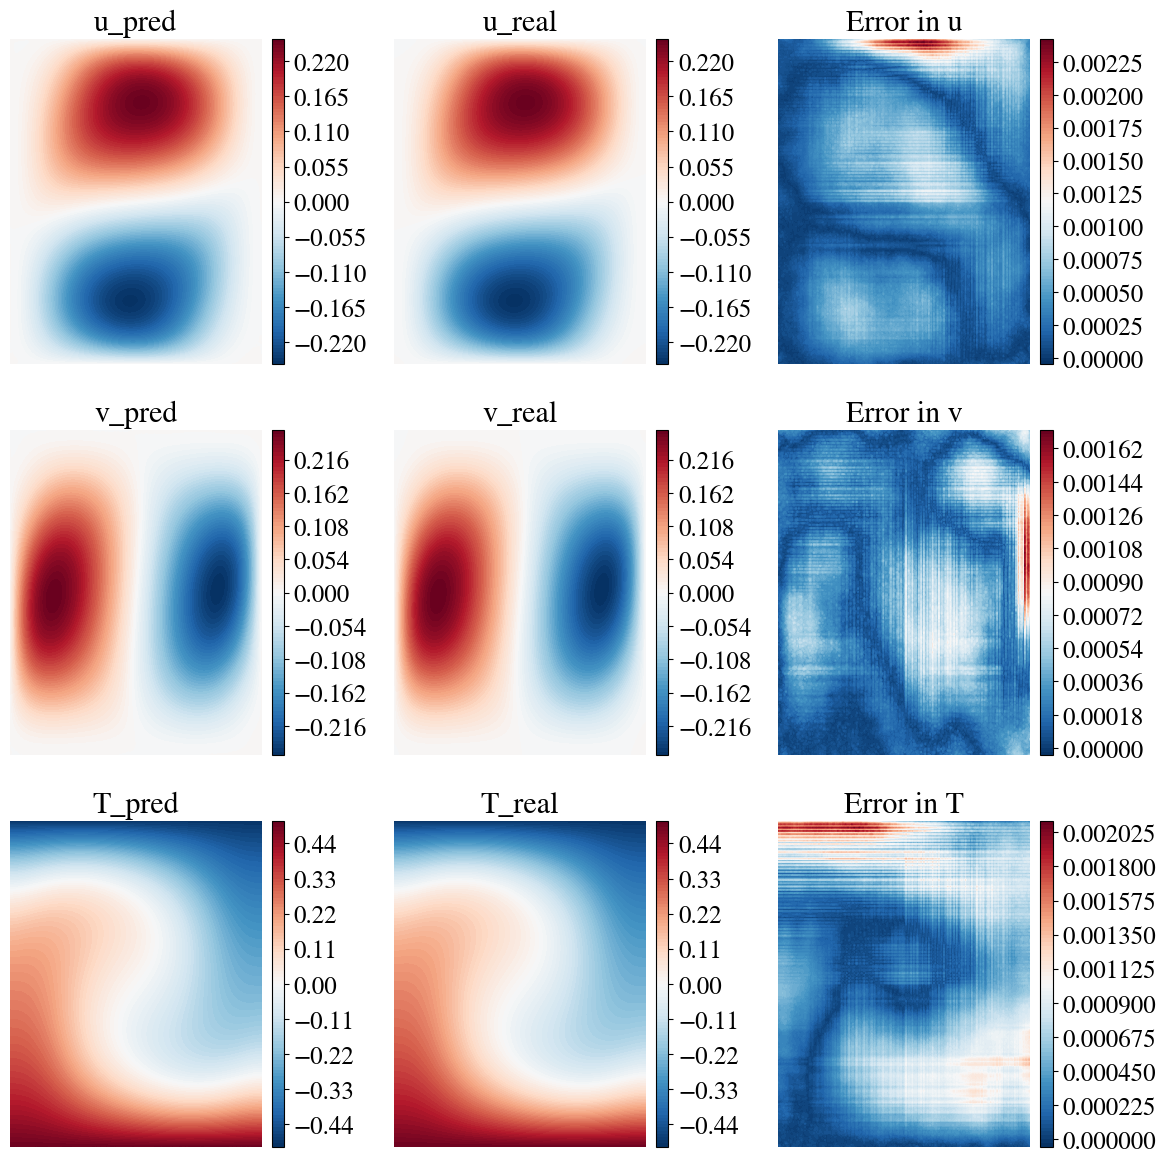

In [ ]:
x = dataset['GT'][:, 0]
y = dataset['GT'][:, 1]
# Calculating errors
error_u = np.abs(u_pred - dataset['GT'][:, 2:3])
error_v = np.abs(v_pred - dataset['GT'][:, 3:4])
error_T = np.abs(T_pred - dataset['GT'][:, 4:5])
def create_contour_subplot(position, values, title):
    ax = plt.subplot(3, 3, position)
    # Create a grid
    xi = np.linspace(x.min(), x.max(), 200)
    yi = np.linspace(y.min(), y.max(), 200)
    X, Y = np.meshgrid(xi, yi)
    
    # Flatten `values` to match the shape of `points`
    Z = griddata((x, y), values.flatten(), (X, Y), method='cubic')  # Interpolation
    # Contour plot
    contour = ax.contourf(X, Y, Z, cmap=cmap, levels=100)
    plt.title(title)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.axis("off")
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.1)
    plt.colorbar(contour, cax=cax)


# Create the figure
plt.figure(figsize=(12, 12))
plt.rcParams.update({'font.size': 18})

# First column: Contour plots of u_pred, v_pred, T_pred
create_contour_subplot(1, u_pred, 'u_pred')
create_contour_subplot(4, v_pred, 'v_pred')
create_contour_subplot(7, T_pred, 'T_pred')

# Second column: Contour plots of real u, v, T values from dataset
create_contour_subplot(2, dataset['GT'][:, 2], 'u_real')
create_contour_subplot(5, dataset['GT'][:, 3], 'v_real')
create_contour_subplot(8, dataset['GT'][:, 4], 'T_real')

# Third column: Contour plots of errors for u, v, T
create_contour_subplot(3, error_u, 'Error in u')
create_contour_subplot(6, error_v, 'Error in v')
create_contour_subplot(9, error_T, 'Error in T')

plt.tight_layout()
plt.savefig(result_path + f'Errors_contour.png')
plt.show()


Compute residuals
$$r_i=u_{NN}(x_i)-u_{real}(x_i)$$
Compute RBA at iteration k:
$$\lambda_i^{k}=\gamma \lambda_i^{k-1}+\eta\frac{|r_i|}{\max_{0\leq j\leq N}r_j}$$
Project them on the simplex (make sure they add up to a constant):
$$\sum_{i}^N\lambda_i=K$$ 
Compute the new loss
$$L=\sum_{i}^N(\lambda_i r_i)^2$$


In [ ]:
def create_scatter_subplot(position, values, title,size=10,cmap='RdBu_r'):
    ax = plt.subplot(2, 2, position)
    scatter = ax.scatter(x, y, c=values, cmap=cmap,s=size)
    plt.title(title)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.axis("off")
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.1)
    plt.colorbar(scatter, cax=cax)


In [ ]:
plt.rcParams.update({'font.size': 12})
# Your existing code
x_data = dataset['Data'][:, 0]
y_data = dataset['Data'][:, 1]
start_plot = 0
end_plot = start_plot + 1
end_plot = len(log_lambdas)
for it in tqdm(range(start_plot, end_plot)):
    idx=log_idxs[it]
    x = dataset['Res'][idx, 0]
    y = dataset['Res'][idx, 1]
    lambdas_it = log_lambdas[it]
    # Creating a figure
    plt.figure(figsize=(8, 8))

    create_scatter_subplot(1, lambdas_it[idx, 0:1], f'lambdas Mx (Iteration {it*100})',size=0.5,cmap='coolwarm')
    create_scatter_subplot(2, lambdas_it[idx, 1:2], f'lambdas My (Iteration {it*100})',size=0.5,cmap='coolwarm')
    create_scatter_subplot(3, lambdas_it[idx, 2:3], f'lambdas MT (Iteration {it*100})',size=0.5,cmap='coolwarm')
    create_scatter_subplot(4, lambdas_it[idx, 3:4], f'lambdas Mass (Iteration {it*100})',size=0.5,cmap='coolwarm')

    plt.savefig(residuals_path + f'Residual_{it/len(log_lambdas):.4f}.png')

    if end_plot == start_plot + 1:
        plt.show()
    else:
        plt.close()


100%|██████████| 1001/1001 [11:18<00:00,  1.48it/s]


In [ ]:
image_folder= residuals_path
video_name=dataset_name+'.mp4'
make_video(image_folder, video_name, 25) # 10 is the FPS (frames per second)


100%|██████████| 1001/1001 [00:21<00:00, 46.16it/s]


In [ ]:
# Create ranges
range1 = np.arange(0, 1001, 100)         # From 0 to 1000 in increments of 100
range2 = np.arange(2000, 10001, 1000)    # From 2000 to 10000 in increments of 1000
range3 = np.arange(15000, 100000, 5000)  # From 15000 to 100000 in increments of 5000

# Concatenate all ranges
all_its = np.concatenate((range1, range2, range3)).tolist()

plt.rcParams.update({'font.size': 12})

# Your existing code

x_data = dataset['Data'][:, 0]
y_data = dataset['Data'][:, 1]
start_plot = 0
end_plot = start_plot + 1
end_plot = len(log_lambdas)
for i in tqdm(range(len(all_its))):
    it=all_its[i]
    idx=log_idxs[it//100]
    x = dataset['Res'][:, 0]
    y = dataset['Res'][:, 1]
    lambdas_it = log_lambdas[it//100]
    # Creating a figure
    plt.figure(figsize=(8, 8))

    create_scatter_subplot(1, lambdas_it[:, 0:1], f'lambdas Mx (Iteration {it})',size=0.5,cmap='coolwarm')
    create_scatter_subplot(2, lambdas_it[:, 1:2], f'lambdas My (Iteration {it})',size=0.5,cmap='coolwarm')
    create_scatter_subplot(3, lambdas_it[:, 2:3], f'lambdas MT (Iteration {it})',size=0.5,cmap='coolwarm')
    create_scatter_subplot(4, lambdas_it[:, 3:4], f'lambdas Mass (Iteration {it})',size=0.5,cmap='coolwarm')

    plt.savefig(lambdas_path + f'Residual_{i/len(all_its):.5f}.png')

    if end_plot == start_plot + 1:
        plt.show()
    else:
        plt.close()


100%|██████████| 37/37 [04:20<00:00,  7.03s/it]


In [ ]:
residuals_path

'/oscar/data/gk/jdtoscan/AIV/Instant-AIV/Results/Rayleight-Bernard/Tilt:Data:1/MMLP:True_AF:sin_Scales_[1, 1, 1]_RBA:True/residuals/'

In [ ]:
image_folder= lambdas_path
video_name=dataset_name+'.mp4'
make_video(image_folder, video_name, 10) # 10 is the FPS (frames per second)


100%|██████████| 37/37 [00:00<00:00, 38.75it/s]


In [ ]:
lambdas_path

'/oscar/data/gk/jdtoscan/AIV/Instant-AIV/Results/Rayleight-Bernard/Tilt:Data:1/MMLP:True_AF:sin_Scales_[1, 1, 1]_RBA:True/lambdas/'